# Predicción de sobrecostos en contratos públicos (SECOP II)

**Trabajo final · Machine Learning I · Maestría**

**Pregunta:** en el momento de **adjudicar** un proceso de contratación, ¿podemos anticipar si el contrato terminará costando más de lo adjudicado?

**Datos** (datos abiertos, [datos.gov.co](https://www.datos.gov.co)):

| Conjunto | ID | Qué aporta |
|---|---|---|
| [SECOP II - Contratos Electrónicos](https://www.datos.gov.co/Estad-sticas-Nacionales/SECOP-II-Contratos-Electr-nicos/jbjy-vk9h) | `jbjy-vk9h` | el contrato: entidad, proveedor, tipo, **valor del contrato (incluye adiciones)** |
| [SECOP II - Procesos de Contratación](https://www.datos.gov.co/Estad-sticas-Nacionales/SECOP-II-Procesos-de-Contrataci-n/p6dx-8zbt) | `p6dx-8zbt` | el proceso: precio base, **valor adjudicado**, duración, competencia |

**Variable objetivo (sobrecosto):**

$$\text{sobrecosto} = \mathbb{1}\left[\ \texttt{valor\_del\_contrato} > \texttt{valor\_total\_adjudicacion}\ \right]$$

Es decir, el contrato **creció después de adjudicado** (adiciones en valor). En SECOP II `valor_del_contrato` se actualiza con las adiciones; lo verificamos más abajo: el crecimiento se concentra justo por debajo de 1,5x, el tope legal de adiciones (art. 40, Ley 80 de 1993).

**Regla de oro:** el modelo solo puede usar información **disponible al adjudicar**. Se excluyen identificadores y cualquier columna que se actualice durante la ejecución del contrato (fuga de información).

## 1. Configuración

In [1]:
import io, time, warnings
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from pandas.api.types import is_numeric_dtype

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, classification_report, confusion_matrix,
                             f1_score, precision_recall_curve, roc_auc_score)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)

ANIO = 2022          # año de firma de los contratos (años viejos = contratos ya terminados)
SEMILLA = 42
API = "https://www.datos.gov.co/resource/{}.csv"
CONTRATOS, PROCESOS = "jbjy-vk9h", "p6dx-8zbt"

## 2. Descarga de datos (API Socrata)

Se descargan solo las columnas necesarias, paginando de a 50.000 filas.

* **Contratos** firmados en `ANIO`, sin *Contratación directa* ni *Régimen especial*: en esas modalidades no hay competencia y el valor adjudicado es, por construcción, el mismo del contrato.
* **Procesos adjudicados** publicados entre el año anterior y `ANIO` (un contrato firmado en enero pudo publicarse meses antes).

> Los identificadores (`proceso_de_compra`, `id_del_portafolio`, `nit_entidad`) se descargan **solo para unir las tablas y para separar entrenamiento/prueba por entidad**; nunca entran al modelo.

In [2]:
COLS_CONTRATOS = [
    # llaves (solo para unir / agrupar)
    "proceso_de_compra", "id_contrato", "nit_entidad",
    # objetivo
    "valor_del_contrato",
    # candidatas (conocidas al adjudicar/firmar)
    "departamento", "orden", "sector", "rama", "entidad_centralizada", "tipo_de_contrato",
    "modalidad_de_contratacion", "codigo_de_categoria_principal", "origen_de_los_recursos",
    "destino_gasto", "es_pyme", "es_grupo", "tipodocproveedor", "habilita_pago_adelantado",
    "el_contrato_puede_ser_prorrogado", "espostconflicto", "obligaci_n_ambiental", "reversion",
    "liquidaci_n", "documentos_tipo", "fecha_de_firma",
    # columnas con fuga: se descargan SOLO para demostrar el efecto en la sección 6
    "estado_contrato", "dias_adicionados", "presupuesto_general_de_la_nacion_pgn",
    "recursos_propios", "fecha_de_inicio_del_contrato", "fecha_de_fin_del_contrato",
    "valor_facturado", "valor_pagado",
]
COLS_PROCESOS = [
    "id_del_portafolio", "precio_base", "valor_total_adjudicacion", "duracion", "unidad_de_duracion",
    "numero_de_lotes", "proveedores_invitados", "proveedores_con_invitacion",
    "respuestas_al_procedimiento", "proveedores_unicos_con", "fecha_de_ultima_publicaci",
]

def descargar(dataset, where, columnas, pagina=50_000):
    partes, offset = [], 0
    while True:
        params = {"$select": ",".join(columnas), "$where": where, "$order": ":id",
                  "$limit": pagina, "$offset": offset}
        for intento in range(5):
            try:
                r = requests.get(API.format(dataset), params=params, timeout=300)
                r.raise_for_status()
                break
            except requests.RequestException:
                time.sleep(2 ** intento)
        else:
            raise RuntimeError("No se pudo descargar la página con offset=" + str(offset))
        df = pd.read_csv(io.StringIO(r.text), dtype=str)
        partes.append(df)
        print(f"  {dataset}: offset={offset:>7,}  filas={len(df):,}")
        if len(df) < pagina:
            return pd.concat(partes, ignore_index=True)
        offset += pagina

contratos = descargar(
    CONTRATOS,
    f"fecha_de_firma between '{ANIO}-01-01' and '{ANIO}-12-31T23:59:59' "
    "and modalidad_de_contratacion not in ('Contratación directa','Contratación régimen especial')",
    COLS_CONTRATOS)
procesos = descargar(
    PROCESOS,
    f"fecha_de_publicacion_del between '{ANIO-1}-01-01' and '{ANIO}-12-31T23:59:59' and adjudicado='Si'",
    COLS_PROCESOS)
print("\ncontratos:", contratos.shape, " procesos:", procesos.shape)

  jbjy-vk9h: offset=      0  filas=50,000


  jbjy-vk9h: offset= 50,000  filas=20,158


  p6dx-8zbt: offset=      0  filas=50,000


  p6dx-8zbt: offset= 50,000  filas=50,000


  p6dx-8zbt: offset=100,000  filas=50,000


  p6dx-8zbt: offset=150,000  filas=44,510

contratos: (70158, 33)  procesos: (194510, 11)


## 3. Limpieza y cruce

1. **Procesos** trae varias filas por proceso (una por publicación). Nos quedamos con la última publicación de cada `id_del_portafolio`.
2. Se cruza `Contratos.proceso_de_compra` = `Procesos.id_del_portafolio`.
3. Solo procesos con **un único contrato**: si un proceso tiene varios lotes/contratos, el valor adjudicado total no se puede repartir entre ellos.
4. Se descartan registros con valores no positivos.

In [3]:
num = lambda s: pd.to_numeric(s, errors="coerce")

contratos = contratos.drop_duplicates("id_contrato")
procesos_u = (procesos.sort_values("fecha_de_ultima_publicaci")
                      .drop_duplicates("id_del_portafolio", keep="last"))
print(f"Procesos: {len(procesos):,} filas -> {len(procesos_u):,} procesos únicos")

n_por_proceso = contratos["proceso_de_compra"].map(contratos["proceso_de_compra"].value_counts())
df = contratos[n_por_proceso == 1].merge(procesos_u, left_on="proceso_de_compra",
                                         right_on="id_del_portafolio", how="inner")
print(f"Contratos: {len(contratos):,} | con un solo contrato por proceso: {(n_por_proceso == 1).sum():,} "
      f"| cruzan con su proceso: {len(df):,}")

df["valor_final"] = num(df["valor_del_contrato"])
df["valor_adjudicado"] = num(df["valor_total_adjudicacion"])
df["precio_base_n"] = num(df["precio_base"])
df = df[(df.valor_final > 0) & (df.valor_adjudicado > 0) & (df.precio_base_n > 0)].reset_index(drop=True)
print(f"Registros finales: {len(df):,}")

Procesos: 194,510 filas -> 120,545 procesos únicos
Contratos: 70,157 | con un solo contrato por proceso: 64,638 | cruzan con su proceso: 62,776


Registros finales: 62,479


## 4. Variable objetivo y verificación de que `valor_del_contrato` incluye las adiciones

El histograma muestra una acumulación justo en 1,5x: las entidades adicionan hasta el tope legal. Los contratos que crecen más de 1,5x violan ese tope y son errores de registro, así que se descartan.

Tasa de sobrecosto: 27.6%  (17,229 de 62,479)

Crecimiento (valor final / adjudicado) en contratos con sobrecosto:
count    1.722900e+04
mean     2.839502e+04
std      3.148838e+06
min      1.000000e+00
10%      1.097000e+00
50%      1.415000e+00
90%      1.502000e+00
99%      1.031800e+01
max      4.050000e+08
dtype: float64

Contratos con crecimiento > 1,5x: 2.79%  (tope legal de adiciones = 50 %)


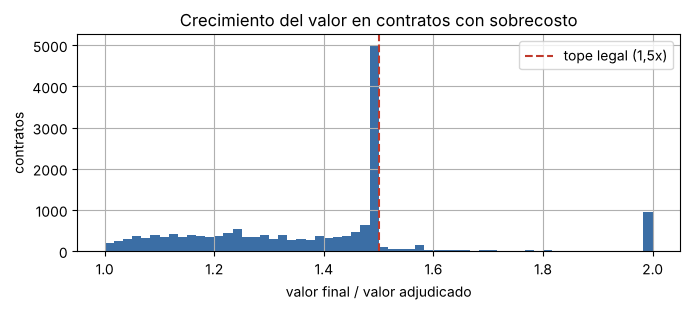

Se descartan 1,743 registros inconsistentes -> quedan 60,736 | tasa de sobrecosto: 25.5%


In [4]:
crecimiento = df.valor_final / df.valor_adjudicado
df["sobrecosto"] = (crecimiento > 1.0001).astype(int)   # tolerancia por redondeo

print(f"Tasa de sobrecosto: {df.sobrecosto.mean():.1%}  ({df.sobrecosto.sum():,} de {len(df):,})")
print("\nCrecimiento (valor final / adjudicado) en contratos con sobrecosto:")
print(crecimiento[df.sobrecosto == 1].describe(percentiles=[.1, .5, .9, .99]).round(3))
print(f"\nContratos con crecimiento > 1,5x: {(crecimiento > 1.5001).mean():.2%}  (tope legal de adiciones = 50 %)")

fig, ax = plt.subplots(figsize=(7, 3.2))
crecimiento[df.sobrecosto == 1].clip(upper=2).hist(bins=60, ax=ax, color="#3b6ea5")
ax.axvline(1.5, color="#c0392b", ls="--", label="tope legal (1,5x)")
ax.set(title="Crecimiento del valor en contratos con sobrecosto",
       xlabel="valor final / valor adjudicado", ylabel="contratos")
ax.legend(); plt.tight_layout(); plt.show()

# Crecer más de 1,5x supera el tope legal: casi siempre es un error de registro del valor adjudicado
# (p. ej. adjudicado = 1 peso). Se descartan esos registros.
inconsistentes = crecimiento > 1.5001
df = df[~inconsistentes].reset_index(drop=True)
print(f"Se descartan {inconsistentes.sum():,} registros inconsistentes -> quedan {len(df):,} "
      f"| tasa de sobrecosto: {df.sobrecosto.mean():.1%}")

In [5]:
print("Tasa de sobrecosto por modalidad:")
display(df.groupby("modalidad_de_contratacion").sobrecosto.agg(tasa="mean", contratos="size")
          .sort_values("contratos", ascending=False).round(3))

Tasa de sobrecosto por modalidad:


,tasa,contratos
modalidad_de_contratacion,,
Mínima cuantía,0.201,35091
Selección Abreviada de Menor Cuantía,0.393,6433
Contratación Directa (con ofertas),0.258,5966
Contratación régimen especial (con ofertas),0.243,4657
Selección abreviada subasta inversa,0.302,4034
Concurso de méritos abierto,0.299,1859
Licitación pública,0.542,1353
Licitación pública Obra Publica,0.564,1130
Seleccion Abreviada Menor Cuantia Sin Manifestacion Interes,0.463,164


## 5. Selección de variables: identificadores y fuga de información

### 5.1 Columnas excluidas

**Identificadores** (únicos por registro o por entidad/persona; no generalizan y permiten memorizar):
`id_contrato`, `referencia_del_contrato`, `proceso_de_compra`, `id_del_proceso`, `id_del_portafolio`, `referencia_del_proceso`, `id_adjudicacion`, `urlproceso`, `nit_entidad`, `codigo_entidad`, `nombre_entidad`, `documento_proveedor`, `codigo_proveedor`, `proveedor_adjudicado`, `nit_del_proveedor_adjudicado`, nombres y documentos de representante legal / supervisor / ordenadores, `c_digo_bpin`, datos bancarios.

**Fuga de información** (se conocen o se actualizan *después* de adjudicar):

| Columna | Por qué hay fuga |
|---|---|
| `valor_del_contrato` | incluye las adiciones: **es** el objetivo |
| `presupuesto_general_de_la_nacion_pgn`, `sistema_general_de_participaciones`, `sistema_general_de_regal_as`, `recursos_propios*`, `recursos_de_credito` | suman el valor **final** del contrato (se verifica abajo) |
| `fecha_de_fin_del_contrato`, `duraci_n_del_contrato` | se mueven con las prórrogas (se verifica abajo) |
| `estado_contrato` | «Modificado» delata la adición |
| `dias_adicionados`, `fecha_de_notificaci_n_de_prorrogaci_n` | prórrogas posteriores |
| `valor_facturado`, `valor_pagado`, `valor_pendiente_*`, `valor_amortizado`, `saldo_cdp`, `saldo_vigencia` | ejecución financiera |
| `estado_del_procedimiento`, `estado_resumen`, `fase`, `ultima_actualizacion`, fechas de liquidación | estados posteriores |

**Texto libre** (`objeto_del_contrato`, `descripcion_del_proceso`): no es fuga, pero queda fuera de este modelo base.

In [6]:
fuentes = sum(num(df[c]).fillna(0) for c in ["presupuesto_general_de_la_nacion_pgn", "recursos_propios"])
dur_fechas = (pd.to_datetime(df.fecha_de_fin_del_contrato, errors="coerce")
              - pd.to_datetime(df.fecha_de_inicio_del_contrato, errors="coerce")).dt.days

evidencia = pd.DataFrame({
    "tasa de sobrecosto": df.groupby("estado_contrato").sobrecosto.mean(),
}).round(3)
print("Sobrecosto según estado_contrato (fuga evidente):"); display(evidencia)
print("Duración mediana según fechas del contrato (días):")
display(dur_fechas.groupby(df.sobrecosto).median().rename({0: "sin sobrecosto", 1: "con sobrecosto"}))
print(f"dias_adicionados > 0: tasa de sobrecosto {df.sobrecosto[num(df.dias_adicionados) > 0].mean():.1%} "
      f"vs {df.sobrecosto[~(num(df.dias_adicionados) > 0)].mean():.1%}")

Sobrecosto según estado_contrato (fuga evidente):


,tasa de sobrecosto
estado_contrato,
Aprobado,0.001
Cerrado,0.220
En ejecución,0.010
Modificado,0.583
Suspendido,0.287
cedido,0.121
terminado,0.286


Duración mediana según fechas del contrato (días):


sobrecosto
sin sobrecosto     77.0
con sobrecosto    213.0
dtype: float64

dias_adicionados > 0: tasa de sobrecosto 53.9% vs 22.3%


### 5.2 Variables del modelo (disponibles al adjudicar)

* **Entidad:** departamento, orden, sector, rama, centralizada/descentralizada.
* **Contrato y proceso:** tipo de contrato, modalidad, categoría UNSPSC (segmento y familia), origen de recursos, destino del gasto, pago anticipado, si puede prorrogarse, obligaciones ambientales, reversión, liquidación, documentos tipo, posconflicto, mes de firma.
* **Montos:** log del precio base, log del valor adjudicado y **descuento** (adjudicado / precio base).
* **Duración pactada** en días (del proceso, no de las fechas del contrato).
* **Competencia:** número de lotes, proveedores invitados, respuestas recibidas, proveedores únicos que respondieron.
* **Proveedor:** pyme, grupo/consorcio, tipo de documento.

In [7]:
CATEGORICAS = ["departamento", "orden", "sector", "rama", "entidad_centralizada", "tipo_de_contrato",
               "modalidad_de_contratacion", "origen_de_los_recursos", "destino_gasto", "es_pyme",
               "es_grupo", "tipodocproveedor", "habilita_pago_adelantado",
               "el_contrato_puede_ser_prorrogado", "espostconflicto", "obligaci_n_ambiental",
               "reversion", "liquidaci_n", "documentos_tipo", "unspsc_segmento", "unspsc_familia"]
NUMERICAS = ["log_precio_base", "log_valor_adjudicado", "adjudicado_sobre_base", "duracion_dias",
             "numero_de_lotes", "proveedores_invitados", "proveedores_con_invitacion",
             "respuestas_al_procedimiento", "proveedores_unicos_con", "mes_firma"]
DIAS = {"día(s)": 1, "Dia(s)": 1, "Semana(s)": 7, "Mes(es)": 30, "Año(s)": 365, "Hora(s)": 1 / 24}

def construir_X(d):
    X = d[CATEGORICAS[:-2]].astype(str).copy()
    unspsc = d.codigo_de_categoria_principal.str.extract(r"V1\.(\d{8})")[0]
    X["unspsc_segmento"] = unspsc.str[:2].fillna("NA")
    X["unspsc_familia"] = unspsc.str[:4].fillna("NA")
    X["log_precio_base"] = np.log1p(d.precio_base_n)
    X["log_valor_adjudicado"] = np.log1p(d.valor_adjudicado)
    X["adjudicado_sobre_base"] = d.valor_adjudicado / d.precio_base_n
    X["duracion_dias"] = num(d.duracion) * d.unidad_de_duracion.map(DIAS)
    for c in ["numero_de_lotes", "proveedores_invitados", "proveedores_con_invitacion",
              "respuestas_al_procedimiento", "proveedores_unicos_con"]:
        X[c] = num(d[c])
    X["mes_firma"] = pd.to_datetime(d.fecha_de_firma, errors="coerce").dt.month
    return X[CATEGORICAS + NUMERICAS]

X = construir_X(df)
y = df.sobrecosto.values
grupos = df.nit_entidad.values   # solo para separar por entidad
print(X.shape); X.head()

(60736, 31)


,departamento,orden,sector,rama,entidad_centralizada,tipo_de_contrato,modalidad_de_contratacion,origen_de_los_recursos,destino_gasto,es_pyme,es_grupo,tipodocproveedor,habilita_pago_adelantado,el_contrato_puede_ser_prorrogado,espostconflicto,obligaci_n_ambiental,reversion,liquidaci_n,documentos_tipo,unspsc_segmento,unspsc_familia,log_precio_base,log_valor_adjudicado,adjudicado_sobre_base,duracion_dias,numero_de_lotes,proveedores_invitados,proveedores_con_invitacion,respuestas_al_procedimiento,proveedores_unicos_con,mes_firma
0,Cesar,Territorial,Servicio Público,Ejecutivo,Descentralizada,Compraventa,Mínima cuantía,Distribuido,Funcionamiento,Si,No,NIT,No,No,No,No,No,Si,No,43,4323,17.901235,17.891182,0.989997,10.0,0,0,0,0,0,12
1,Cundinamarca,Nacional,Ley de Justicia,Corporación Autónoma,Centralizada,Suministros,Mínima cuantía,Distribuido,Funcionamiento,Si,No,Cédula de Ciudadanía,No,No,No,No,No,No,No,82,8210,16.118096,16.118096,1.000000,270.0,0,0,0,5,5,3
2,Distrito Capital de Bogotá,Territorial,Salud y Protección Social,Ejecutivo,Centralizada,Seguros,Selección Abreviada de Menor Cuantía,Distribuido,Funcionamiento,No,No,NIT,No,Si,No,No,No,No,No,84,8413,18.051808,17.762120,0.748497,280.0,2,4,4,2,2,6
3,Tolima,Territorial,Servicio Público,Ejecutivo,Centralizada,Prestación de servicios,Mínima cuantía,Distribuido,Inversión,Si,No,NIT,No,No,No,No,No,No,No,81,8116,17.466169,17.426428,0.961039,70.0,0,0,0,0,0,10
4,Cauca,Nacional,Trabajo,Ejecutivo,Centralizada,Compraventa,Mínima cuantía,Recursos Propios,Inversión,Si,No,NIT,No,No,No,No,No,No,No,45,4511,15.836688,15.661539,0.839331,30.0,0,0,0,0,0,11


## 6. Partición entrenamiento / prueba por entidad

Una misma entidad contrata de forma parecida; si sus contratos quedan a ambos lados de la partición, el modelo «reconoce» a la entidad y la métrica se infla. Por eso el set de prueba tiene **entidades que el modelo nunca vio** (`GroupShuffleSplit`, 25 %).

In [8]:
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEMILLA).split(X, y, grupos))
X_tr, X_te, y_tr, y_te = X.iloc[tr], X.iloc[te], y[tr], y[te]
print(f"Entrenamiento: {len(tr):,} contratos, {len(set(grupos[tr])):,} entidades | tasa {y_tr.mean():.1%}")
print(f"Prueba:        {len(te):,} contratos, {len(set(grupos[te])):,} entidades | tasa {y_te.mean():.1%}")
assert not set(grupos[tr]) & set(grupos[te])

Entrenamiento: 46,846 contratos, 1,412 entidades | tasa 25.8%
Prueba:        13,890 contratos, 471 entidades | tasa 24.6%


## 7. Modelos

Clases desbalanceadas → métrica principal **PR-AUC** (precisión promedio); también ROC-AUC y F1. Un clasificador al azar tiene PR-AUC igual a la tasa de positivos.

1. **Línea base:** siempre predice la clase mayoritaria.
2. **Regresión logística** con *one-hot* y estandarización.
3. **Gradient Boosting** (`HistGradientBoostingClassifier`) con variables categóricas nativas.

In [9]:
# niveles aprendidos SOLO en entrenamiento (máx. 250 por columna); lo demás -> "OTRA"
NIVELES = {c: X_tr[c].value_counts().index[:250].tolist() for c in CATEGORICAS}

def a_categorias(D):
    D = D.copy()
    for c in CATEGORICAS:
        D[c] = pd.Categorical(D[c].where(D[c].isin(NIVELES[c]), "OTRA"), categories=NIVELES[c] + ["OTRA"])
    return D

def evaluar(nombre, p, umbral=0.5):
    return {"modelo": nombre, "ROC-AUC": roc_auc_score(y_te, p),
            "PR-AUC": average_precision_score(y_te, p), "F1": f1_score(y_te, p >= umbral)}

resultados = []

base = DummyClassifier(strategy="prior").fit(X_tr, y_tr)
resultados.append(evaluar("Línea base (tasa promedio)", base.predict_proba(X_te)[:, 1]))

logit = Pipeline([
    ("prep", ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30), CATEGORICAS),
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), NUMERICAS),
    ])),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced")),
]).fit(X_tr, y_tr)
resultados.append(evaluar("Regresión logística", logit.predict_proba(X_te)[:, 1]))

Xc_tr, Xc_te = a_categorias(X_tr), a_categorias(X_te)
gb = HistGradientBoostingClassifier(max_iter=400, learning_rate=0.06, max_leaf_nodes=31,
                                    l2_regularization=1.0, categorical_features="from_dtype",
                                    early_stopping=True, validation_fraction=0.15,
                                    random_state=SEMILLA).fit(Xc_tr, y_tr)
p_gb = gb.predict_proba(Xc_te)[:, 1]

# umbral elegido en ENTRENAMIENTO (máximo F1), nunca en prueba
p_tr = gb.predict_proba(Xc_tr)[:, 1]
prec, rec, umb = precision_recall_curve(y_tr, p_tr)
umbral = umb[np.nanargmax(2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12))]
resultados.append(evaluar("Gradient Boosting", p_gb, umbral))

tabla = pd.DataFrame(resultados).set_index("modelo").round(3)
tabla

,ROC-AUC,PR-AUC,F1
modelo,,,
Línea base (tasa promedio),0.500,0.246,0.000
Regresión logística,0.737,0.470,0.509
Gradient Boosting,0.768,0.527,0.532


In [10]:
print(f"Umbral de decisión (elegido en entrenamiento): {umbral:.3f}\n")
print(classification_report(y_te, p_gb >= umbral, target_names=["sin sobrecosto", "con sobrecosto"]))
print("Matriz de confusión [filas = real, columnas = predicho]:")
print(confusion_matrix(y_te, p_gb >= umbral))

Umbral de decisión (elegido en entrenamiento): 0.318

                precision    recall  f1-score   support

sin sobrecosto       0.86      0.78      0.82     10474
con sobrecosto       0.48      0.60      0.53      3416

      accuracy                           0.74     13890
     macro avg       0.67      0.69      0.68     13890
  weighted avg       0.76      0.74      0.75     13890

Matriz de confusión [filas = real, columnas = predicho]:
[[8198 2276]
 [1354 2062]]


### Importancia de variables (permutación sobre el set de prueba)

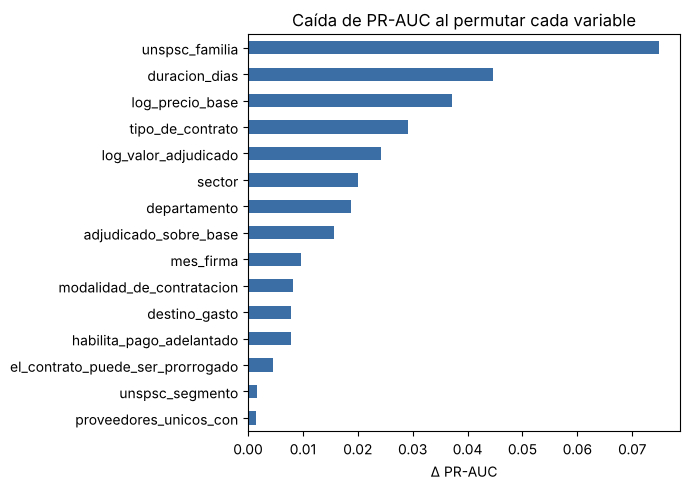

In [11]:
imp = permutation_importance(gb, Xc_te, y_te, scoring="average_precision", n_repeats=5,
                             random_state=SEMILLA, n_jobs=-1)
importancia = pd.Series(imp.importances_mean, index=Xc_te.columns).sort_values()
ax = importancia.tail(15).plot.barh(figsize=(7, 5), color="#3b6ea5")
ax.set(title="Caída de PR-AUC al permutar cada variable", xlabel="Δ PR-AUC")
plt.tight_layout(); plt.show()

## 8. ¿Cuánto infla la fuga de información las métricas?

Mismo modelo y misma partición, agregando columnas con fuga. Estas cifras **no son válidas**: se muestran para justificar la exclusión.

In [12]:
def con_extras(extras):
    A, B = Xc_tr.copy(), Xc_te.copy()
    for nombre, serie in extras.items():
        A[nombre], B[nombre] = serie.iloc[tr].values, serie.iloc[te].values
    m = HistGradientBoostingClassifier(max_iter=400, learning_rate=0.06, categorical_features="from_dtype",
                                       random_state=SEMILLA).fit(A, y_tr)
    return m.predict_proba(B)[:, 1]

estado = df.estado_contrato.astype("category")
fuga = {
    "estado_contrato": estado,
    "dias_adicionados": num(df.dias_adicionados),
    "fuente_pgn": num(df.presupuesto_general_de_la_nacion_pgn),
    "fuente_recursos_propios": num(df.recursos_propios),
    "duracion_por_fechas": dur_fechas,
}
comparacion = pd.DataFrame([
    evaluar("Limpio (al adjudicar)", p_gb, umbral),
    evaluar("+ fuga (estado, días adicionados, fuentes, fechas)", con_extras(fuga), umbral),
    evaluar("+ fuga total (valor_del_contrato)", con_extras({**fuga, "log_valor_final": np.log1p(df.valor_final)}), umbral),
]).set_index("modelo").round(3)
comparacion

,ROC-AUC,PR-AUC,F1
modelo,,,
Limpio (al adjudicar),0.768,0.527,0.532
"+ fuga (estado, días adicionados, fuentes, fechas)",0.916,0.802,0.721
+ fuga total (valor_del_contrato),0.992,0.983,0.937


## 9. Conclusiones

* La llave entre las dos tablas es `proceso_de_compra` ↔ `id_del_portafolio`.
* `valor_del_contrato` **incluye las adiciones** (crecimiento máximo ≈ 1,5x, el tope legal), así que *valor final > valor adjudicado* es una medida directa de sobrecosto.
* Varias columnas aparentemente inocentes tienen **fuga**: las fuentes de financiación suman el valor final y las fechas de fin se mueven con las prórrogas. Incluirlas infla el desempeño (ver sección 8).
* El modelo limpio se evalúa sobre **entidades no vistas** y supera claramente a la línea base; lo que más pesa es el tipo de bien o servicio (familia UNSPSC), la duración pactada, el monto (precio base y valor adjudicado) y el tipo de contrato.

**Limitaciones:** se descartan los registros que superan el tope legal de 1,5x (errores de registro); algunos contratos aún pueden recibir adiciones (etiqueta incompleta); solo se usan procesos con un contrato; se excluye la contratación directa. **Trabajo futuro:** usar varios años con validación temporal, el texto del objeto del contrato y el historial de la entidad calculado solo con contratos anteriores.